In [ ]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots

from ipywidgets import Dropdown, IntSlider, interact

plt.style.use("ICIWstyle")

In [4]:
from HSA_Cam_C_002_numpyro import (
    kl_divergence_between_models,
)
from HSA_Mo_C_001_numpyro import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    sample_prior,
    sample_posterior,
    validate_against_holdout,
    TRUE_PARAMS,
)

In [5]:
# exp_run_name = "scornful-placebo"  # VI small test
exp_run_name = "convoluted-sympathy"  # full run with optimized settings
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [6]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [7]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.add_groups({"prior": sample_prior(4000).prior})
    else:
        idata.add_groups({"prior": idatas[i - 1].posterior})

In [8]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [9]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [10]:
display(proposals)

array([[5.57312622e+02, 6.02359056e+00, 2.87816346e-01, 2.62025547e+01,
        6.87129700e+02, 8.21177542e-01],
       [4.50000000e+02, 3.00000000e+00, 2.00000003e-01, 5.00000000e-01,
        5.00000000e-01, 5.00000007e-02],
       [6.00000000e+02, 3.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        5.00000000e-01, 5.00000007e-02],
       [6.00000000e+02, 9.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        1.00000000e+03, 5.00000007e-02],
       [5.25000000e+02, 6.00000000e+00, 2.09999990e+00, 5.00250000e+02,
        5.00250000e+02, 5.24999976e-01],
       [4.50000000e+02, 9.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        1.00000000e+03, 1.00000000e+00],
       [6.00000000e+02, 3.00000000e+00, 4.00000000e+00, 5.00000000e-01,
        5.00000000e-01, 1.00000000e+00],
       [6.00000000e+02, 3.00000000e+00, 4.00000000e+00, 5.00000000e-01,
        5.00000000e-01, 5.00000007e-02],
       [4.50000000e+02, 3.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        5.00000000e-01, 

### Visualize the training success

In [11]:
@interact(
    i=IntSlider(
        min=0,
        max=proposals.shape[0] - 1,
        step=1,
        value=0,
        description="Experiment Index",
    ),
    j=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    ),
)
def interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$t$ / h",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        # yscale="log",
        # ylim=(1e-6, 1e-5),
        # xlim=(450, 600),
    )

    T_prop = proposals[j : j + 1, 0:1]
    p_prop = proposals[j : j + 1, 1:2]
    c2h_prop = proposals[j : j + 1, 2:3]
    c2m_prop = proposals[j : j + 1, 3:4]
    c2w_prop = proposals[j : j + 1, 4:5]
    c2i_prop = proposals[j : j + 1, 5:6]

    pi_prop = calculate_partial_pressures(
        p_total=p_prop,
        c2h_ratio=c2h_prop,
        c2m_ratio=c2m_prop,
        c2w_ratio=c2w_prop,
        c2i_ratio=c2i_prop,
    )

    r_pred = predict(
        idatas[i],
        T_prop,
        pi_prop,
        key="prior" if i == 0 else "posterior",
    )
    display(i, j)
    display(r_pred.shape)

    ax.plot(r_obs[:, j, 0, 0], "ro", label="Observed data")
    ax.plot(r_pred.mean(axis=3)[:, 0, 0], label="Predicted data")
    ax.fill_between(
        jnp.arange(r_pred.shape[0]),
        jnp.quantile(r_pred[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred[:, 0, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Experiment Index', max=25), IntSlider(value=0, descripti…

16

16

(10, 1, 1, 25)

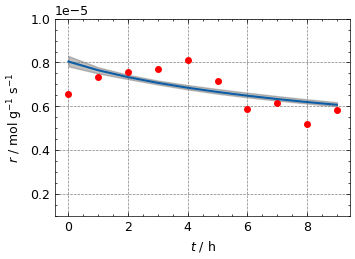

In [16]:
interactive(16, 16)  # (10,0) & (16,16)
fig = plt.gcf()
plt.savefig("figures/ODE_example_1.svg")

### Visualize the experimental plan

/tmp/ipykernel_1596/2292498082.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



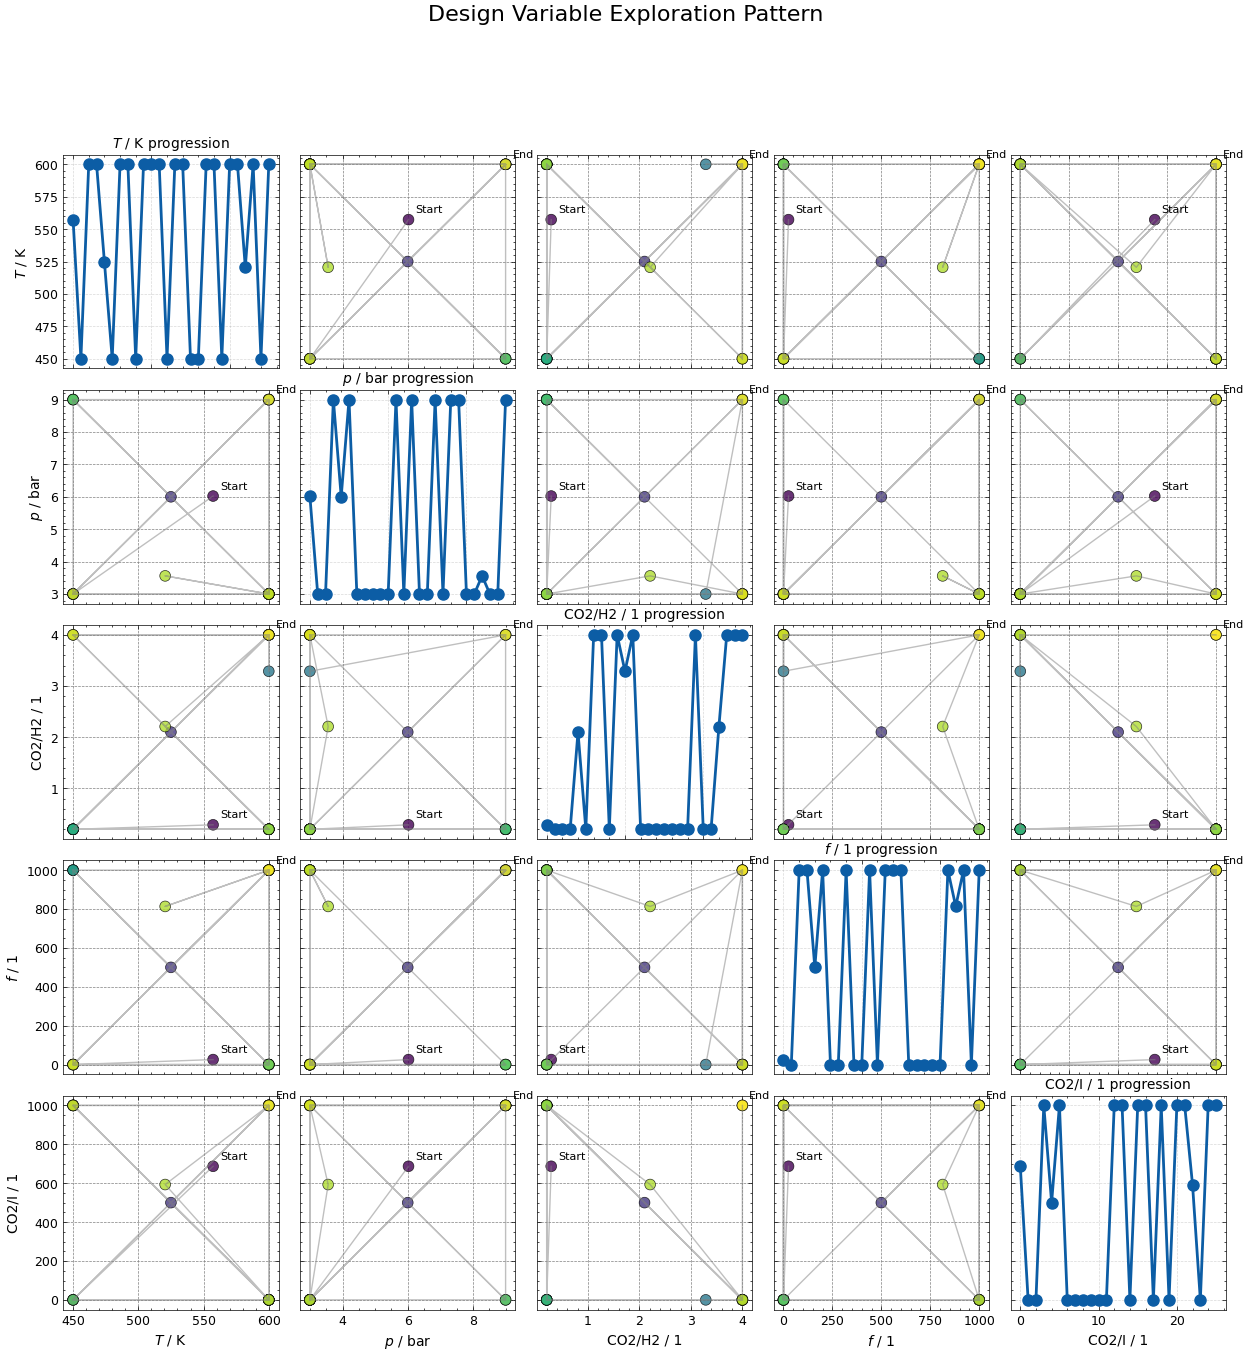

In [12]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

### Observe the parameter progression

In [13]:
print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['Ea_deact', 'Ea_k', 'k0', 'k_deact', 'n_deact', 'r_lat', 'sigma_r', 't_Ea_deact', 't_Ea_k', 't_k0', 't_k_deact', 't_n_deact']


interactive(children=(Dropdown(description='Parameter:', index=2, options=('Ea_deact', 'Ea_k', 'k0', 'k_deact'…

In [14]:
az.summary(idatas[-1])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_deact[0],32664.172,4117.478,25052.711,40450.461,31.132,25.532,17369.0,18141.0,1.0
Ea_k[0],77175.539,415.027,76379.453,77944.758,3.135,2.518,17563.0,18820.0,1.0
k0[0],0.000,0.000,0.000,0.000,0.000,0.000,16701.0,18832.0,1.0
k_deact[0],0.000,0.000,0.000,0.000,0.000,0.000,14929.0,17471.0,1.0
n_deact[0],5.422,0.493,4.517,6.355,0.004,0.003,16539.0,18407.0,1.0
...,...,...,...,...,...,...,...,...,...
t_Ea_deact,-0.434,0.127,-0.671,-0.196,0.001,0.001,17369.0,18141.0,1.0
t_Ea_k,0.434,0.005,0.424,0.444,0.000,0.000,17563.0,18820.0,1.0
t_k0,1.239,0.015,1.210,1.267,0.000,0.000,16701.0,18832.0,1.0
t_k_deact,1.114,0.168,0.794,1.424,0.001,0.001,14929.0,17471.0,1.0


In [15]:
@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
    i=IntSlider(
        min=0,
        max=len(idatas) - 1,
        step=1,
        value=0,
        description="Inference Step",
    ),
)
def interactive(key, i):
    az.plot_dist_comparison(
        idatas[i],
        var_names=key,
    )

interactive(children=(Dropdown(description='Parameter:', index=2, options=('Ea_deact', 'Ea_k', 'k0', 'k_deact'…

### Validate against holdout data

In [16]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_C_001.nc"))
display(test_data)

<xarray.Dataset> Size: 160kB
Dimensions:    (sample: 1000, parameter: 6, species: 5, time: 10, component: 1,
                draws: 1)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
  * time       (time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * component  (component) <U1 4B 'a'
  * draws      (draws) int64 8B 0
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float32 4kB ...
    p          (sample, species) float32 20kB ...
    latent_r   (time, sample, component, draws) float32 40kB ...
    obs_r      (time, sample, component, draws) float32 40kB ...
Attributes:
    noise:    homoscedastic
    sigma:    1e-05

In [17]:
postdatas = []
for idata in idatas:
    postdata = validate_against_holdout(idata, test_data, num_samples=985)
    postdatas.append(postdata)

(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


...

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



In [18]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[
        var_name
    ].values  # shape (chain=1, draw=1, obs, times=10, 1)
    pred = postdata.posterior_predictive[
        var_name
    ].values  # shape (chain=1, draw, obs, times=10, n_samples)
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=(2, 3, 4))).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da

In [19]:
RMSEs = []
for postdata in postdatas:
    RMSEs.append(bRMSE(postdata, "r_lat"))

RMSEs = np.array(RMSEs)

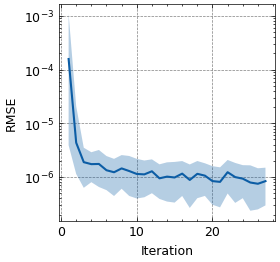

In [20]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEs) + 1), RMSEs.mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEs) + 1),
    np.quantile(RMSEs, 0.025, axis=1),
    np.quantile(RMSEs, 0.975, axis=1),
    alpha=0.3,
)

### Quantify information gain

In [21]:
info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "k_deact",
            "Ea_deact",
            "n_deact",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[ 2.93847939  0.02080109  0.667385    0.05300198  0.48457536 16.4836914 ]
20.647934221995488
[0.5231212  3.7882871  0.08329118 0.5766707  0.52000604 0.8349811 ]
6.32635731406584
[0.28105471 0.04069968 0.13846077 0.83756491 0.22109426 4.48197276]
6.0008470910443386
[0.10555683 0.1430607  0.09244898 0.95031289 0.14992398 0.45944727]
1.9007506617360548
[0.06206071 0.80415359 0.26136549 0.18863172 0.16307223 0.32399697]
1.803280708006619
[0.06127913 1.45572873 0.22890068 0.05885638 0.26080189 0.3195503 ]
2.3851171100475175
[0.08980935 0.42319879 0.09489455 3.69641854 0.21574497 1.62325478]
6.143320978182828
[0.08898682 0.56727817 0.47668012 0.64559062 0.74262847 0.03694753]
2.558111716094202
[0.05699627 1.39814187 0.52192914 1.29885781 0.65192632 2.13647249]
6.064323910454162
[0.06796293 0.09388365 0.00470548 0.06764238 0.02248125 0.02214669]
0.27882239311900525
[0.01220759 0.06574475 0.06949663 0.35465094 0.04016302 0.03093512]
0.5731980463569075
[0.13214701 0.00728801 0.87681577 0.418718

Text(0, 0.5, 'info gain as per KL divergence')

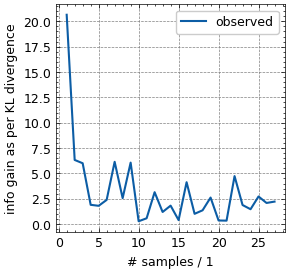

In [22]:
plt.plot(np.arange(len(kldses)) + 1, kldses, label="observed")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [23]:
info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[0],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "k_deact",
            "Ea_deact",
            "n_deact",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[ 2.62573328  0.0438139   0.7153398   0.03606604  0.51207459 16.25071834]
20.183745950090497
[ 3.33069337  3.78088055  0.49318436  0.34033186  0.29598447 28.25914615]
36.500220752464635
[ 3.59252523  4.69817514  0.8714596   1.34312482  0.75237039 31.57884762]
42.83650280616815
[ 3.67352817  3.30221078  1.08949222  1.34314214  1.19697134 31.61952199]
42.224866628969174
[ 3.83815264  4.15629993  1.22716879  1.56275371  1.18354085 31.71590845]
43.68382437289432
[ 4.0123526   5.12905844  1.42082904  1.67819073  1.11423819 31.74514837]
45.099817383641394
[ 3.74498209  3.9333089   1.28421295  1.86954288  1.14897852 31.76097039]
43.74199572789426
[ 3.80388476  5.46394352  1.44518722  1.76279645  1.02909489 31.75202158]
45.25692842284322
[ 3.8491576   3.48231979  1.19710884  1.84901128  1.1330219  31.72912018]
43.239739593854225
[ 4.06269053  5.2109355   1.25375117  1.83039394  1.12986251 31.77451691]
45.26215055687099
[ 4.06091311  3.49807854  1.36886409  1.67160595  1.1910821  31.80458806]
4

Text(0, 0.5, 'info gain as per KL divergence')

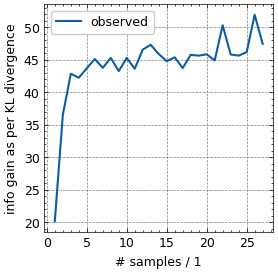

In [24]:
plt.plot(np.arange(len(kldses)) + 1, kldses, label="observed")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")